# Forecasting tomorrow's PM2.5: ARIMA vs machine learning

**Goal:** predict tomorrow's average PM2.5 in Beijing, so the city can warn people and plan actions (for example traffic limits) before a bad pollution day.

**Set-up**
- Train: March 2013 to February 2016 (3 years)
- Test: March 2016 to February 2017 (the last 365 days, never seen during training)
- Each day in the test year I forecast the **next day only**, using information available up to that day (walk-forward, no data leakage)
- Metrics: MAE and RMSE in µg/m³, plus how well each model warns about days above China's limit (75 µg/m³)

**Models compared**
1. Naive: tomorrow = today (the baseline every model must beat)
2. 7-day moving average
3. ARIMA on log PM2.5
4. Linear Regression, Random Forest and Gradient Boosting using lag features
5. The same ML models with **tomorrow's weather forecast** added

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, precision_score, recall_score

sns.set_style("whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)
CHINA_LIMIT = 75

## 1. Prepare the daily data

In [2]:
hourly = pd.read_csv("../data/beijing_hourly_city.csv", parse_dates=["datetime"], index_col="datetime")
daily = hourly.drop(columns="wd").resample("D").mean()
daily["RAIN"] = hourly["RAIN"].resample("D").sum()
y = daily["PM2.5"]

train_end = "2016-02-29"
test_start = "2016-03-01"
y_test = y[test_start:]
print("Train days:", len(y[:train_end]), "| Test days:", len(y_test))

Train days: 1096 | Test days: 365


In [3]:
# helper to store results
results = []
predictions = pd.DataFrame({"actual": y_test})

def evaluate(name, pred):
    pred = pd.Series(pred, index=y_test.index).clip(lower=0)   # PM2.5 cannot be negative
    predictions[name] = pred
    actual_bad = y_test > CHINA_LIMIT
    pred_bad = pred > CHINA_LIMIT
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Bad days caught (recall %)": recall_score(actual_bad, pred_bad) * 100,
        "Warnings correct (precision %)": precision_score(actual_bad, pred_bad) * 100,
    })

## 2. Baselines

In [4]:
# naive: tomorrow will be the same as today
evaluate("Naive (yesterday's value)", y.shift(1)[test_start:])

# average of the last 7 days
evaluate("7-day moving average", y.rolling(7).mean().shift(1)[test_start:])

pd.DataFrame(results)

,Model,MAE,RMSE,Bad days caught (recall %),Warnings correct (precision %)
0,Naive (yesterday's value),43.22,63.17,62.07,62.07
1,7-day moving average,52.64,71.98,48.97,46.10


## 3. ARIMA
The EDA showed the series is stationary, so d = 0. I compare a few small models on the training data using AIC (lower is better).

In [5]:
log_y = np.log(y)
log_train = log_y[:train_end]

aic_table = []
for order in [(1, 0, 0), (2, 0, 0), (3, 0, 0), (1, 0, 1), (2, 0, 1), (2, 0, 2)]:
    m = ARIMA(log_train, order=order).fit()
    aic_table.append({"order": str(order), "AIC": m.aic})

aic_table = pd.DataFrame(aic_table).sort_values("AIC")
aic_table

,order,AIC
1,"(2, 0, 0)",2390.64
2,"(3, 0, 0)",2392.59
4,"(2, 0, 1)",2392.60
5,"(2, 0, 2)",2393.74
3,"(1, 0, 1)",2396.81
0,"(1, 0, 0)",2432.33


In [6]:
best_order = eval(aic_table.iloc[0]["order"])   # the order with the lowest AIC
print("Chosen order:", best_order)
arima_fit = ARIMA(log_train, order=best_order).fit()
print(arima_fit.summary().tables[1])

# walk-forward: keep the fitted parameters, feed in the real data day by day
# and take the one-step-ahead forecast for each test day
arima_all = arima_fit.apply(log_y)
arima_pred = np.exp(arima_all.get_prediction(start=test_start).predicted_mean)
arima_name = "ARIMA(%d,%d,%d) on log PM2.5" % best_order
evaluate(arima_name, arima_pred)

Chosen order: (2, 0, 0)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.0506      0.044     91.963      0.000       3.964       4.137
ar.L1          0.6390      0.031     20.506      0.000       0.578       0.700
ar.L2         -0.1981      0.031     -6.366      0.000      -0.259      -0.137
sigma2         0.5146      0.023     22.294      0.000       0.469       0.560


## 4. Machine learning models
I turn the time series into a table. Each row is a day, and the features only use information known **up to the day before**:
- PM2.5 of the last 1, 2, 3 and 7 days, and the 3-day and 7-day averages
- Yesterday's weather (temperature, pressure, dew point, wind speed, rain)
- Month (as sine and cosine so December is close to January) and day of week

In [7]:
features = pd.DataFrame(index=daily.index)
for lag in [1, 2, 3, 7]:
    features[f"pm25_lag{lag}"] = y.shift(lag)
features["pm25_avg3"] = y.shift(1).rolling(3).mean()
features["pm25_avg7"] = y.shift(1).rolling(7).mean()

weather = ["TEMP", "PRES", "DEWP", "WSPM", "RAIN"]
for col in weather:
    features[f"{col}_yesterday"] = daily[col].shift(1)

features["month_sin"] = np.sin(2 * np.pi * daily.index.month / 12)
features["month_cos"] = np.cos(2 * np.pi * daily.index.month / 12)
features["day_of_week"] = daily.index.dayofweek

features = features.dropna()
features.head()

,pm25_lag1,pm25_lag2,pm25_lag3,pm25_lag7,pm25_avg3,pm25_avg7,TEMP_yesterday,PRES_yesterday,DEWP_yesterday,WSPM_yesterday,RAIN_yesterday,month_sin,month_cos,day_of_week
datetime,,,,,,,,,,,,,,
2013-03-08,241.02,203.79,125.35,7.33,190.05,101.43,9.11,1001.98,-2.63,1.24,0.00,1.00,0.00,4
2013-03-09,201.43,241.02,203.79,31.47,215.41,129.16,10.05,999.11,-2.05,1.81,0.00,1.00,0.00,5
2013-03-10,60.32,201.43,241.02,79.29,167.59,133.28,7.07,1004.06,-11.18,3.56,0.00,1.00,0.00,6
2013-03-11,37.01,60.32,201.43,21.77,99.59,127.24,5.69,1020.16,-14.45,2.25,0.00,1.00,0.00,0
2013-03-12,122.84,37.01,60.32,125.35,73.39,141.68,5.98,1013.37,-7.46,1.41,0.00,1.00,0.00,1


In [8]:
def train_and_test(X, label):
    X_train, X_test = X[:train_end], X[test_start:]
    y_train = y.loc[X_train.index]
    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    }
    fitted = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        evaluate(f"{name} ({label})", model.predict(X_test))
        fitted[name] = model
    return fitted

ml_models = train_and_test(features, "past data only")
pd.DataFrame(results).round(1)

,Model,MAE,RMSE,Bad days caught (recall %),Warnings correct (precision %)
0,Naive (yesterday's value),43.20,63.20,62.10,62.10
1,7-day moving average,52.60,72.00,49.00,46.10
2,"ARIMA(2,0,0) on log PM2.5",39.70,59.50,53.10,67.50
3,Linear Regression (past data only),36.40,52.50,71.70,63.80
4,Random Forest (past data only),34.80,51.10,75.20,68.10
5,Gradient Boosting (past data only),35.40,51.90,72.40,68.20


## 5. What if we also have tomorrow's weather forecast?
Weather forecasts for the next day are usually quite accurate, and the EDA showed wind is strongly linked to pollution.
Here I add the weather of the day being predicted. I use the real measured weather as a stand-in for a good forecast, so this is an **upper bound**: a real forecast would have some error.

In [9]:
features_wx = features.copy()
for col in weather:
    features_wx[f"{col}_forecast"] = daily.loc[features_wx.index, col]

wx_models = train_and_test(features_wx, "with weather forecast")

## 6. Results

In [10]:
results_df = pd.DataFrame(results).set_index("Model").round(1)
results_df.sort_values("MAE")

,MAE,RMSE,Bad days caught (recall %),Warnings correct (precision %)
Model,,,,
Gradient Boosting (with weather forecast),23.80,35.20,77.20,73.70
Random Forest (with weather forecast),25.20,35.70,75.20,69.90
Linear Regression (with weather forecast),25.80,37.00,85.50,70.90
Random Forest (past data only),34.80,51.10,75.20,68.10
Gradient Boosting (past data only),35.40,51.90,72.40,68.20
Linear Regression (past data only),36.40,52.50,71.70,63.80
"ARIMA(2,0,0) on log PM2.5",39.70,59.50,53.10,67.50
Naive (yesterday's value),43.20,63.20,62.10,62.10
7-day moving average,52.60,72.00,49.00,46.10


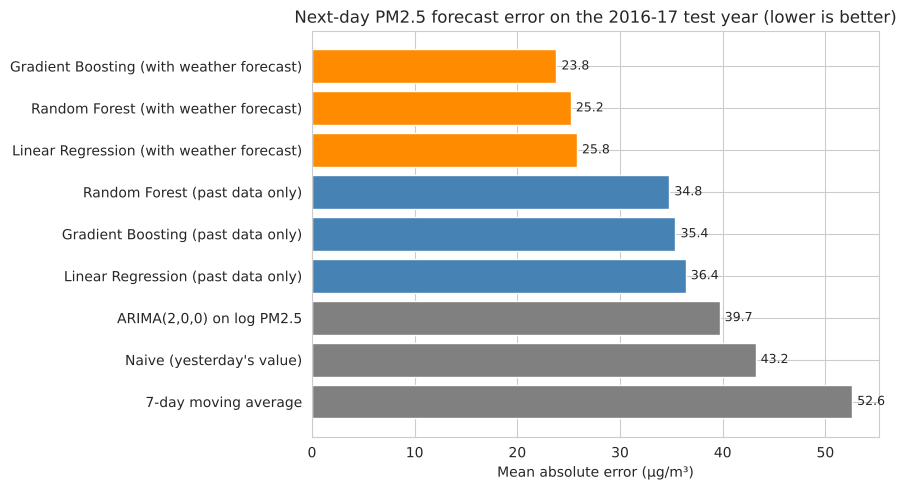

In [11]:
plot_df = results_df.sort_values("MAE", ascending=False)
colours = ["darkorange" if "weather" in m else ("steelblue" if "past" in m else "grey") for m in plot_df.index]

plt.figure(figsize=(9, 5))
bars = plt.barh(plot_df.index, plot_df["MAE"], color=colours)
for b, v in zip(bars, plot_df["MAE"]):
    plt.text(v + 0.5, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", fontsize=9)
plt.title("Next-day PM2.5 forecast error on the 2016-17 test year (lower is better)")
plt.xlabel("Mean absolute error (µg/m³)")
plt.tight_layout()
plt.savefig("../images/06_model_comparison.png", dpi=150)
plt.show()

In [12]:
naive = results_df.loc["Naive (yesterday's value)", "MAE"]
arima = results_df.loc[arima_name, "MAE"]
rf = results_df.loc["Random Forest (past data only)", "MAE"]
best_wx = results_df.loc[[i for i in results_df.index if "weather" in i], "MAE"].min()

print(f"ARIMA vs naive:                 {(naive - arima) / naive * 100:.0f}% lower error")
print(f"Random Forest vs naive:         {(naive - rf) / naive * 100:.0f}% lower error")
print(f"Best model with weather vs naive: {(naive - best_wx) / naive * 100:.0f}% lower error")

ARIMA vs naive:                 8% lower error
Random Forest vs naive:         19% lower error
Best model with weather vs naive: 45% lower error


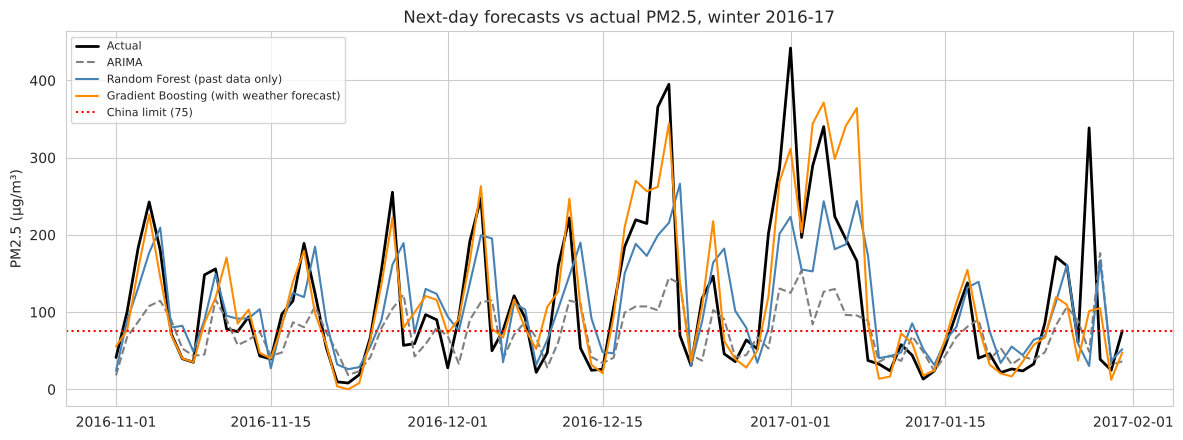

In [13]:
# forecasts vs actual for one winter period in the test year
period = slice("2016-11-01", "2017-01-31")
plt.figure(figsize=(12, 4.5))
plt.plot(predictions.loc[period, "actual"], color="black", linewidth=2, label="Actual")
plt.plot(predictions.loc[period, arima_name], color="grey", linestyle="--", label="ARIMA")
plt.plot(predictions.loc[period, "Random Forest (past data only)"], color="steelblue", label="Random Forest (past data only)")
plt.plot(predictions.loc[period, "Gradient Boosting (with weather forecast)"], color="darkorange", label="Gradient Boosting (with weather forecast)")
plt.axhline(CHINA_LIMIT, color="red", linestyle=":", label="China limit (75)")
plt.title("Next-day forecasts vs actual PM2.5, winter 2016-17")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("../images/07_forecast_vs_actual.png", dpi=150)
plt.show()

Models using only past data react **one day late**: they follow yesterday's value, so they miss the start and the end of a pollution episode.
Adding the weather forecast lets the model see the change coming (for example a strong north wind that will clear the air).

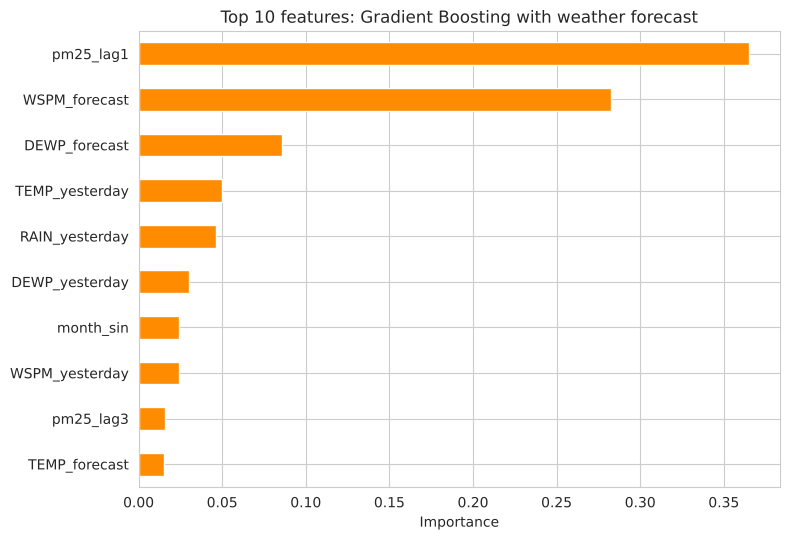

pm25_lag1        0.37
WSPM_forecast    0.28
DEWP_forecast    0.09
TEMP_yesterday   0.05
RAIN_yesterday   0.05
dtype: float64

In [14]:
# which features matter most for the best model?
gb = wx_models["Gradient Boosting"]
importance = pd.Series(gb.feature_importances_, index=features_wx.columns).sort_values()

plt.figure(figsize=(8, 5.5))
importance.tail(10).plot(kind="barh", color="darkorange")
plt.title("Top 10 features: Gradient Boosting with weather forecast")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("../images/08_feature_importance.png", dpi=150)
plt.show()

importance.sort_values(ascending=False).head(5)

## 7. Conclusions

1. **Machine learning beats ARIMA.** ARIMA is fitted on log PM2.5, and turning the forecast back with exp() gives a typical (median) value, which is lower than the average on spiky days. That is one reason it catches only about half of the bad days. It still improves on the naive forecast, but Random Forest with lag and weather features is clearly better because it can use weather and season, not only past PM2.5.
2. **The weather forecast is the key.** Adding tomorrow's wind speed and dew point cuts the error a lot. Pollution in Beijing is driven by weather (wind clears it, calm humid air traps it), so an early-warning system should be built on weather forecasts, not only past pollution.
3. **Warnings for bad days.** The best model with weather catches most of the days above China's limit, and most of its warnings are correct. That makes it useful for public health alerts.
4. **Limitations.** The weather-forecast models use measured weather as a perfect forecast, so real errors would be a bit higher. The models predict the city average only (not each station), and the data ends in 2017, so it does not include later policy changes.

**Next steps:** use real archived weather forecasts, predict 2 to 3 days ahead, and try SARIMAX (ARIMA with weather inputs) or LSTM models.